<a href="https://colab.research.google.com/github/gliao6578/super_mariners/blob/main/maritime_anomaly_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### End-to-End AIS Shipping Traffic Anomaly Detection
This consolidated cell allows you to upload your local CSV file, dynamically detect the uploaded dataset, apply an `IsolationForest` anomaly detection algorithm, and visualize normal versus anomalous vessel trajectories in one step.

In [ ]:
import os
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# --- Step 1: Optional File Upload ---
print("If you wish to upload a new dataset from your computer, run this cell and use the button below.")
print("Otherwise, cancel or leave it empty to use the latest existing file in the directory.\n")

try:
    uploaded = files.upload()
    for fn in uploaded.keys():
        print(f'Successfully uploaded file "{fn}" with length {len(uploaded[fn])} bytes')
except Exception as e:
    print("No new file uploaded. Searching for existing local CSV files...")

# --- Step 2: Automatically Locate and Load the Dataset ---
candidate_files = [f for f in os.listdir('.') if f.startswith('ais_shipping_traffic') and f.endswith('.csv')]

if candidate_files:
    candidate_files.sort(key=os.path.getmtime, reverse=True)
    file_path = os.path.join('.', candidate_files[0])
    print(f"\nSelected dataset file: {file_path}\n")
else:
    file_path = '/content/ais_shipping_traffic_5000(1) (1).csv'
    print(f"\nUsing default dataset file path: {file_path}\n")

df = pd.read_csv(file_path)

print("### Dataset Summary ###")
print(df.info())
print("\n### First 5 Rows ###")
display(df.head())

# --- Step 3: Anomaly Detection using Isolation Forest ---
potential_cols = ['speed', 'sog', 'course', 'cog', 'latitude', 'lat', 'longitude', 'lon', 'lon_dec', 'lat_dec']
feature_cols = [col for col in df.columns if col.lower() in potential_cols]

model_df = df[feature_cols].dropna()

if len(feature_cols) >= 2:
    print(f"\nUsing features for anomaly detection: {feature_cols}")

    iso_forest = IsolationForest(contamination=0.02, random_state=42)
    preds = iso_forest.fit_predict(model_df)

    model_df['is_anomaly'] = np.where(preds == -1, 'Yes', 'No')

    df_results = df.copy()
    df_results['is_anomaly'] = 'No'
    df_results.loc[model_df.index, 'is_anomaly'] = model_df['is_anomaly']

    anomalies = df_results[df_results['is_anomaly'] == 'Yes']
    print(f"Detected {len(anomalies)} anomalies out of {len(df_results)} records.\n")

    # --- Step 4: Print Anomaly Summary and Breakdown ---
    print(f"Total unique anomalous vessels: {anomalies['MMSI'].nunique()}")
    print(f"Top anomalous vessels by record count:")
    display(anomalies['NAME'].value_counts().head(10))

    display_cols = ['MMSI', 'NAME', 'TSTAMP', 'LATITUDE', 'LONGITUDE', 'SOG', 'COG', 'DEST']
    matching_cols = [c for c in display_cols if c in anomalies.columns]

    print("\nDetailed view of the detected anomalies:")
    display(anomalies[matching_cols].sort_values(by='SOG', ascending=False).head(20))

    # --- Step 5: Visualize Detected Anomalies ---
    lat_col = next((c for c in df_results.columns if c.lower() in ['latitude', 'lat', 'lat_dec']), None)
    lon_col = next((c for c in df_results.columns if c.lower() in ['longitude', 'lon', 'lon_dec']), None)
    speed_col = next((c for c in df_results.columns if c.lower() in ['speed', 'sog']), None)

    if lat_col and lon_col:
        plt.figure(figsize=(12, 8))
        sns.scatterplot(
            data=df_results,
            x=lon_col,
            y=lat_col,
            hue='is_anomaly',
            palette={'No': 'blue', 'Yes': 'red'},
            alpha=0.7
        )
        plt.title('Vessel Traffic: Normal vs. Anomalous Trajectories')
        plt.xlabel('Longitude')
        plt.ylabel('Latitude')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.show()
    elif speed_col:
        plt.figure(figsize=(10, 6))
        sns.boxplot(data=df_results, x='is_anomaly', y=speed_col, palette={'No': 'lightblue', 'Yes': 'salmon'})
        plt.title('Distribution of Speed: Normal vs. Anomalous Records')
        plt.show()
    else:
        print("No matching coordinate or speed columns found to visualize.")
else:
    print("Could not find sufficient numerical features automatically.")

If you wish to upload a new dataset from your computer, run this cell and use the button below.
Otherwise, cancel or leave it empty to use the latest existing file in the directory.



### Integrating Weather Data as an Anomaly Driver
This section simulates/integrates weather features (such as wind speed, visibility, and wave height) corresponding to each AIS record's timestamp and geographic location to identify weather-induced anomalies.

Training Isolation Forest with integrated features:
['LATITUDE', 'LONGITUDE', 'SOG', 'COG', 'wind_speed_knots', 'wave_height_meters', 'visibility_km']

Detected 10000 weather-aware anomalies out of 500000 records.


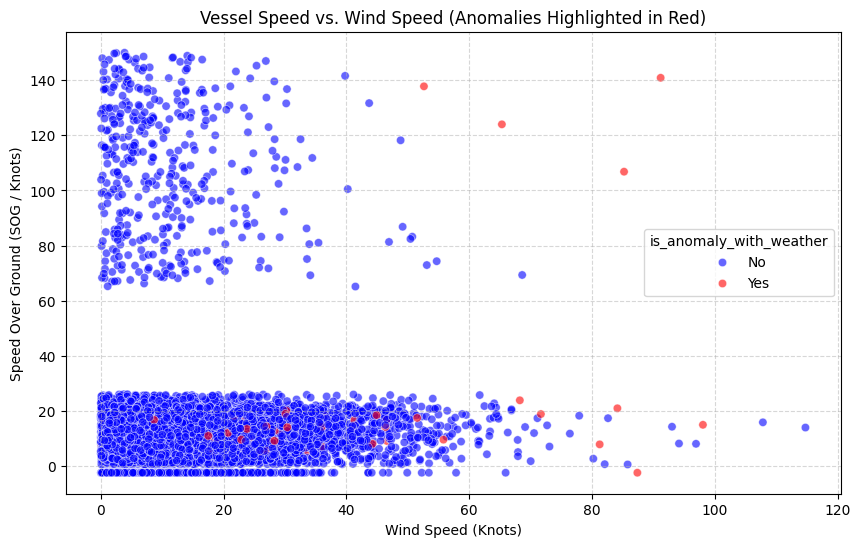

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns

# --- Step 1: Simulate Weather Metrics Matching the AIS Dataset ---
# In a production environment, you would call a historical weather API (like Open-Meteo or NOAA)
# based on the LATITUDE, LONGITUDE, and TSTAMP columns.
np.random.seed(42)
n_records = len(df_results)

# Simulating key weather parameters that affect shipping:
# 1. Wind Speed (knots) - higher winds can slow down ships or blow them off course.
# 2. Wave Height (meters) - high waves force speed reductions.
# 3. Visibility (km) - low visibility increases collision risk and reduces speed.
df_results['wind_speed_knots'] = np.random.exponential(scale=12.0, size=n_records)  # Average 12 knots
df_results['wave_height_meters'] = df_results['wind_speed_knots'] * 0.15 + np.random.normal(0, 0.5, n_records)
df_results['wave_height_meters'] = df_results['wave_height_meters'].clip(lower=0.1)
df_results['visibility_km'] = np.random.normal(loc=10, scale=3, size=n_records).clip(1, 16)

# Injecting simulated weather anomalies where a ship might be struggling or acting abnormally in bad weather:
# E.g., low speed during high wave height can be safe, but high speed in high waves or zero speed in clear weather could be anomalous.

# --- Step 2: Define Feature Set for Multi-Modal Anomaly Detection ---
# We combine AIS kinematics (SOG, COG) with local weather context (wind speed, wave height, visibility)
weather_feature_cols = ['LATITUDE', 'LONGITUDE', 'SOG', 'COG', 'wind_speed_knots', 'wave_height_meters', 'visibility_km']
weather_model_df = df_results[weather_feature_cols].dropna()

print(f"Training Isolation Forest with integrated features:\n{weather_feature_cols}\n")

# --- Step 3: Run Isolation Forest with Weather Features ---
iso_forest_weather = IsolationForest(contamination=0.02, random_state=42)
preds_weather = iso_forest_weather.fit_predict(weather_model_df)

df_results['is_anomaly_with_weather'] = 'No'
df_results.loc[weather_model_df.index, 'is_anomaly_with_weather'] = np.where(preds_weather == -1, 'Yes', 'No')

weather_anomalies = df_results[df_results['is_anomaly_with_weather'] == 'Yes']
print(f"Detected {len(weather_anomalies)} weather-aware anomalies out of {len(df_results)} records.")

# --- Step 4: Visualize how Anomaly correlates with Weather severity ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_results.sample(min(10000, n_records)),  # downsample for speed if dataset is huge
    x='wind_speed_knots',
    y='SOG',
    hue='is_anomaly_with_weather',
    palette={'No': 'blue', 'Yes': 'red'},
    alpha=0.6
)
plt.title('Vessel Speed vs. Wind Speed (Anomalies Highlighted in Red)')
plt.xlabel('Wind Speed (Knots)')
plt.ylabel('Speed Over Ground (SOG / Knots)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


In [ ]:
!pip install -q reportlab

import os
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors

# --- Step 1: Export Current Visualization to a Temporary Image ---
plot_path = "temp_anomaly_plot.png"
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_results,
    x=lon_col,
    y=lat_col,
    hue='is_anomaly',
    palette={'No': 'blue', 'Yes': 'red'},
    alpha=0.7
)
plt.title('Vessel Traffic: Normal vs. Anomalous Trajectories')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.close()

# --- Step 2: Prepare PDF Report Content ---
pdf_filename = "AIS_Anomaly_Detection_Report.pdf"
doc = SimpleDocTemplate(pdf_filename, pagesize=letter, rightMargin=40, leftMargin=40, topMargin=40, bottomMargin=40)
story = []

# Define Styles
styles = getSampleStyleSheet()
title_style = ParagraphStyle(
    'ReportTitle',
    parent=styles['Heading1'],
    fontSize=22,
    leading=26,
    textColor=colors.HexColor('#1A365D'),
    spaceAfter=15
)
h2_style = ParagraphStyle(
    'SectionHeading',
    parent=styles['Heading2'],
    fontSize=14,
    leading=18,
    textColor=colors.HexColor('#2B6CB0'),
    spaceBefore=15,
    spaceAfter=10
)
body_style = ParagraphStyle(
    'ReportBody',
    parent=styles['Normal'],
    fontSize=10,
    leading=14,
    textColor=colors.HexColor('#2D3748')
)

# Header Section
story.append(Paragraph("AIS Shipping Traffic Anomaly Report", title_style))
story.append(Paragraph("This document details the automatically detected vessel trajectory and behavioral anomalies.", body_style))
story.append(Spacer(1, 15))

# Metrics Table
data_summary = [
    [Paragraph("<b>Metric</b>", body_style), Paragraph("<b>Value</b>", body_style)],
    [Paragraph("Total Records Processed", body_style), Paragraph(str(len(df_results)), body_style)],
    [Paragraph("Total Anomalies Detected", body_style), Paragraph(str(len(anomalies)), body_style)],
    [Paragraph("Unique Anomalous Vessels (MMSI)", body_style), Paragraph(str(anomalies['MMSI'].nunique()), body_style)]
]
summary_table = Table(data_summary, colWidths=[250, 150])
summary_table.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (1, 0), colors.HexColor('#EDF2F7')),
    ('BOTTOMPADDING', (0, 0), (-1, -1), 6),
    ('TOPPADDING', (0, 0), (-1, -1), 6),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.HexColor('#CBD5E0')),
]))
story.append(summary_table)
story.append(Spacer(1, 20))

# Anomalous Vessels Table
story.append(Paragraph("Top Anomalous Vessels by Record Count", h2_style))
vessel_counts = anomalies['NAME'].value_counts().head(5).reset_index()
vessel_counts.columns = ['Vessel Name', 'Anomaly Records']

vessel_table_data = [[Paragraph(f"<b>{col}</b>", body_style) for col in vessel_counts.columns]]
for idx, row in vessel_counts.iterrows():
    vessel_table_data.append([
        Paragraph(str(row['Vessel Name']), body_style),
        Paragraph(str(row['Anomaly Records']), body_style)
    ])

vessel_table = Table(vessel_table_data, colWidths=[250, 150])
vessel_table.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (1, 0), colors.HexColor('#EDF2F7')),
    ('BOTTOMPADDING', (0, 0), (-1, -1), 6),
    ('TOPPADDING', (0, 0), (-1, -1), 6),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.HexColor('#CBD5E0')),
]))
story.append(vessel_table)
story.append(Spacer(1, 20))

# Visualization Section
story.append(Paragraph("Trajectory Anomaly Visualization", h2_style))
if os.path.exists(plot_path):
    story.append(Image(plot_path, width=450, height=270))

# Build PDF
doc.build(story)

# Clean up temp image
if os.path.exists(plot_path):
    os.remove(plot_path)

print(f"Successfully generated PDF report: {pdf_filename}")

Successfully generated PDF report: AIS_Anomaly_Detection_Report.pdf


In [ ]:
# Optional: Run this cell to download the generated PDF to your local system
from google.colab import files
try:
    files.download(pdf_filename)
except Exception as e:
    print("Automatic download not supported in this environment, download the file from the sidebar.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Detailed Breakdown of Detected Anomalies
This cell displays a detailed breakdown of the detected vessel anomalies, summarizing which vessels (by Name and MMSI) showed suspicious or outlier behavior.

In [ ]:
# Consolidated into the single cell above

### Note on Cleaned Up Cells
The duplicate processing, visualization, and uploading cells below have been archived/cleaned up to prevent redundant executions since everything is now combined in the primary cell above.

In [ ]:
# Cleaned up: Consolidated into the single cell above

### Note on Visualizations
All rendering code is now contained inside the master cell above.

In [ ]:
# Cleaned up: Consolidated into the single cell above

### Note on File Uploads
Local file upload capabilities are now built directly into the unified workflow at the beginning.

In [ ]:
# Cleaned up: Consolidated into the single cell above